# Sentiment Analysis on Customer Reviews
**End-to-end workflow:** EDA, rating normalization, cleaning, binary sentiment labeling, visualization, model comparison, testing and joblib export.

This notebook keeps only the `Review` and `Rating` fields, as requested.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, re, joblib, os
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from pipeline_utils import clean_text, normalize_rating, prepare_data, make_model
sns.set_theme(style='whitegrid')

In [2]:
df=pd.read_csv('reviews_data.csv')
print('Shape:',df.shape); print(df.dtypes); display(df.head())

Shape: (850, 6)
name            object
location        object
Date            object
Rating         float64
Review          object
Image_Links     object
dtype: object


,name,location,Date,Rating,Review,Image_Links
0,Helen,"Wichita Falls, TX","Reviewed Sept. 13, 2023",5.0,Amber and LaDonna at the Starbucks on Southwes...,['No Images']
1,Courtney,"Apopka, FL","Reviewed July 16, 2023",5.0,** at the Starbucks by the fire station on 436...,['No Images']
2,Daynelle,"Cranberry Twp, PA","Reviewed July 5, 2023",5.0,I just wanted to go out of my way to recognize...,['https://media.consumeraffairs.com/files/cach...
3,Taylor,"Seattle, WA","Reviewed May 26, 2023",5.0,Me and my friend were at Starbucks and my card...,['No Images']
4,Tenessa,"Gresham, OR","Reviewed Jan. 22, 2023",5.0,I’m on this kick of drinking 5 cups of warm wa...,['https://media.consumeraffairs.com/files/cach...


In [3]:
print('Missing values:'); display(df.isna().sum()); print('Duplicates:',df.duplicated().sum()); print('Rating values:'); display(df['Rating'].value_counts(dropna=False)); print('Review empty:',df['Review'].astype(str).str.strip().eq('').sum())

Missing values:


name             0
location         0
Date             0
Rating         145
Review           0
Image_Links      0
dtype: int64

Duplicates: 1
Rating values:


Rating
1.0    451
NaN    145
2.0     99
5.0     83
4.0     39
3.0     33
Name: count, dtype: int64

Review empty: 0


In [4]:
subset=df[['Review','Rating']].copy()
subset['Rating_Normalized']=subset['Rating'].apply(normalize_rating)
print('Unparseable/missing rating rows:',subset['Rating_Normalized'].isna().sum()); display(subset['Rating_Normalized'].value_counts(dropna=False))

Unparseable/missing rating rows: 145


Rating_Normalized
1.0    451
NaN    145
2.0     99
5.0     83
4.0     39
3.0     33
Name: count, dtype: int64

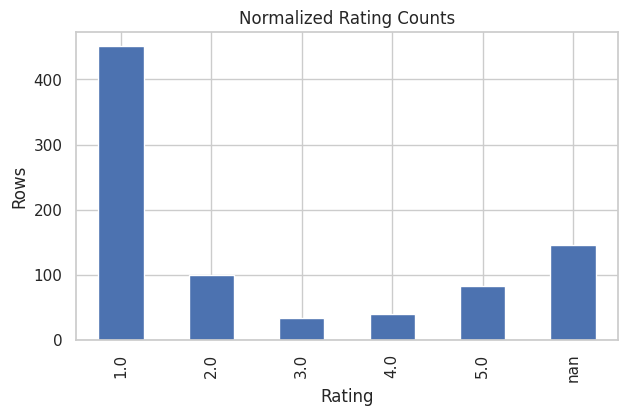

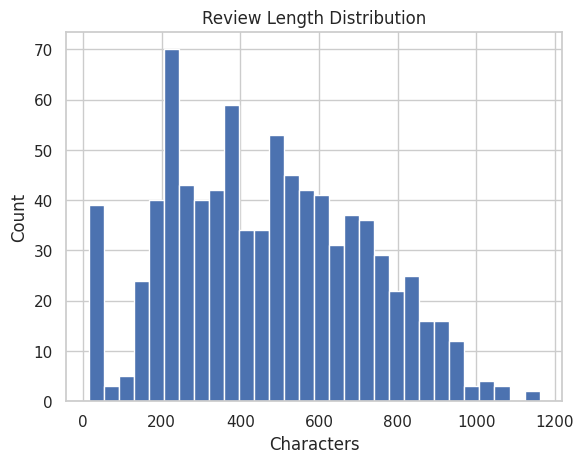

In [5]:
fig,ax=plt.subplots(figsize=(7,4)); subset['Rating_Normalized'].value_counts(dropna=False).sort_index().plot(kind='bar',ax=ax); ax.set_title('Normalized Rating Counts'); ax.set_xlabel('Rating'); ax.set_ylabel('Rows'); plt.show()
lengths=df['Review'].astype(str).str.len(); lengths.hist(bins=30); plt.title('Review Length Distribution'); plt.xlabel('Characters'); plt.ylabel('Count'); plt.show()

In [6]:
clean=prepare_data(df)
print('Rows after filtering, deduplication, neutral removal and cleaning:',len(clean)); print(clean['Sentiment'].value_counts()); display(clean.head())

Rows after filtering, deduplication, neutral removal and cleaning: 672
Sentiment
Negative    550
Positive    122
Name: count, dtype: int64


,Review,Rating,Sentiment,Clean_Review
0,Amber and LaDonna at the Starbucks on Southwes...,5.0,Positive,amber ladonna starbucks southwest parkway alwa...
1,** at the Starbucks by the fire station on 436...,5.0,Positive,starbucks fire station altamonte springs fl ma...
2,I just wanted to go out of my way to recognize...,5.0,Positive,wanted go way recognize starbucks employee bil...
3,Me and my friend were at Starbucks and my card...,5.0,Positive,friend starbucks card didn work thankful worke...
4,I’m on this kick of drinking 5 cups of warm wa...,5.0,Positive,kick drinking cups warm water work instacart r...


In [7]:
print('Before:',clean.loc[0,'Review']); print('\nAfter:',clean.loc[0,'Clean_Review'])

Before: Amber and LaDonna at the Starbucks on Southwest Parkway are always so warm and welcoming. There is always a smile in their voice when they greet you at the drive-thru. And their customer service is always spot-on, they always get my order right and with a smile. I would actually give them more than 5 stars if they were available.

After: amber ladonna starbucks southwest parkway always warm welcoming always smile their voice greet drive thru their customer service always spot always get order right smile would actually give stars available


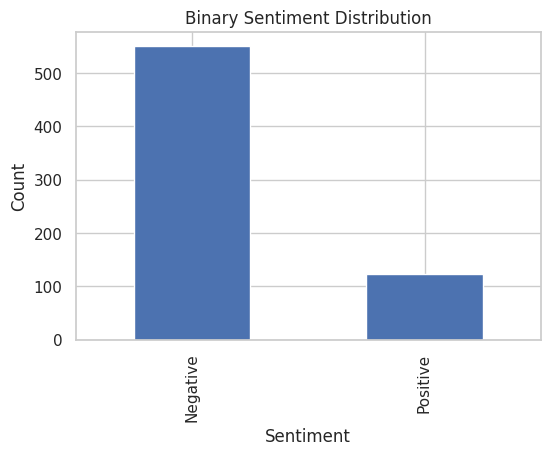

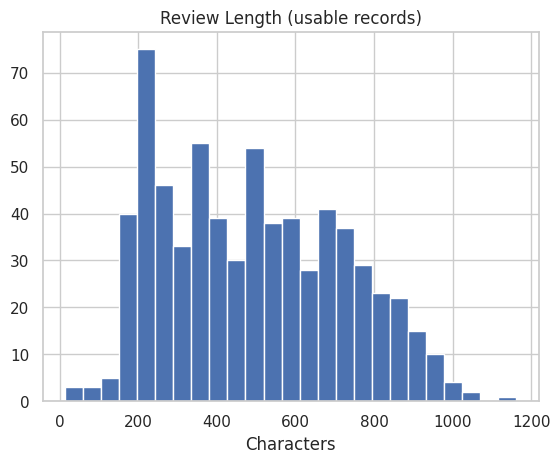

In [8]:
plt.figure(figsize=(6,4)); clean['Sentiment'].value_counts().plot(kind='bar'); plt.title('Binary Sentiment Distribution'); plt.ylabel('Count'); plt.show()
clean['review_length']=clean['Review'].str.len(); clean['review_length'].hist(bins=25); plt.title('Review Length (usable records)'); plt.xlabel('Characters'); plt.show()

,Word,Frequency
0,starbucks,126
1,coffee,86
2,always,60
3,service,55
4,great,47
5,their,46
6,not,39
7,customer,37
8,store,37
9,good,36


,Word,Frequency
0,starbucks,775
1,not,439
2,coffee,395
3,customer,223
4,drink,210
5,get,208
6,no,203
7,one,191
8,service,180
9,store,179


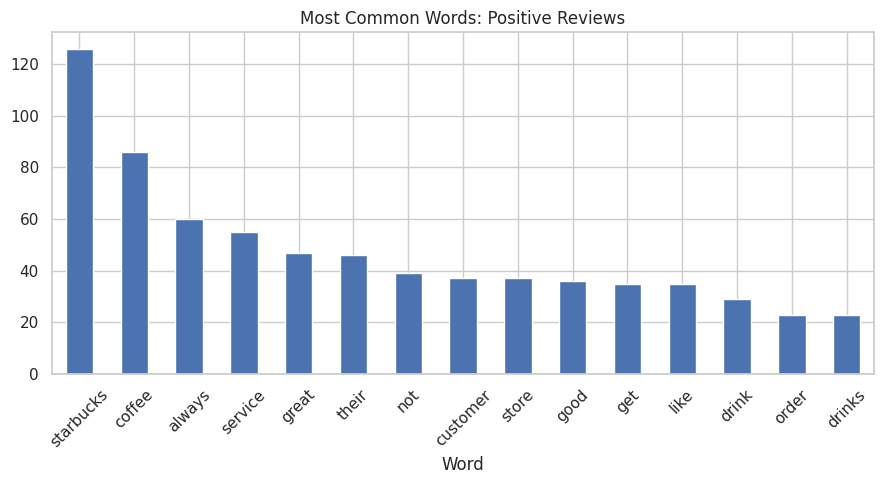

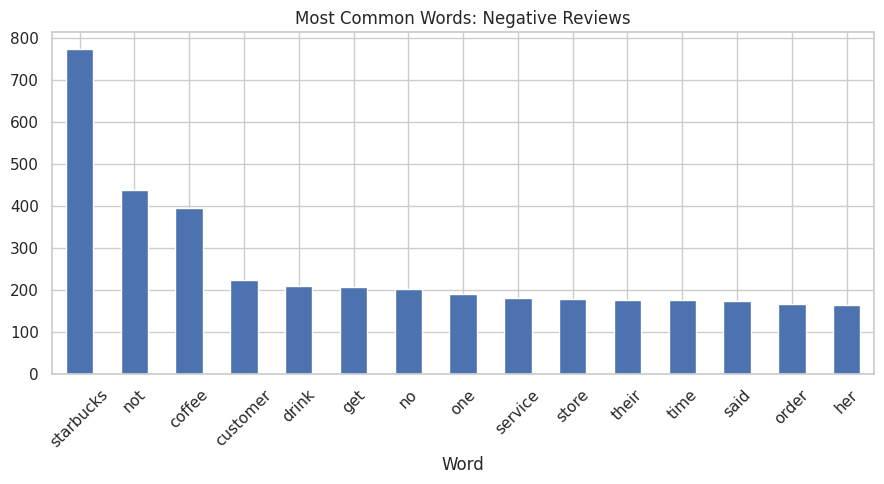

In [9]:
def top_words(frame,label,n=15):
    words=' '.join(frame.loc[frame.Sentiment==label,'Clean_Review']).split()
    return pd.DataFrame(Counter(words).most_common(n),columns=['Word','Frequency'])
positive_words=top_words(clean,'Positive'); negative_words=top_words(clean,'Negative')
display(positive_words,negative_words)
fig,ax=plt.subplots(figsize=(9,5)); positive_words.set_index('Word')['Frequency'].plot(kind='bar',ax=ax); ax.set_title('Most Common Words: Positive Reviews'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(9,5)); negative_words.set_index('Word')['Frequency'].plot(kind='bar',ax=ax); ax.set_title('Most Common Words: Negative Reviews'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### Cleaning decisions
- Missing or invalid ratings are removed because sentiment labels cannot be assigned reliably.
- Ratings 1–2 map to Negative and 4–5 map to Positive; rating 3 is neutral and excluded for a binary task.
- Duplicate review/rating pairs are removed.
- Text is lowercased, links and punctuation removed, and common stop words filtered. Negations such as **not**, **no**, and **never** are preserved because they can reverse sentiment.

In [10]:
X=clean['Clean_Review']; y=clean['Sentiment']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print('Train:',len(X_train),'Test:',len(X_test)); print('Training label proportions:\n',y_train.value_counts(normalize=True))

Train: 537 Test: 135
Training label proportions:
 Sentiment
Negative    0.819367
Positive    0.180633
Name: proportion, dtype: float64



 Multinomial Naive Bayes {'accuracy': 0.8148148148148148, 'precision_positive': 0.0, 'recall_positive': 0.0, 'f1_positive': 0.0}
              precision    recall  f1-score   support

    Negative       0.81      1.00      0.90       110
    Positive       0.00      0.00      0.00        25

    accuracy                           0.81       135
   macro avg       0.41      0.50      0.45       135
weighted avg       0.66      0.81      0.73       135



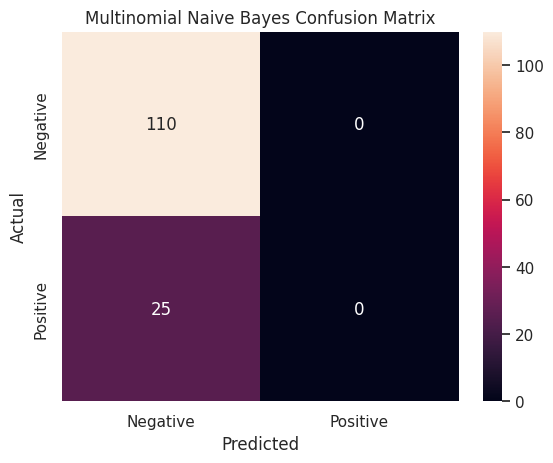


 Logistic Regression {'accuracy': 0.9259259259259259, 'precision_positive': 0.8947368421052632, 'recall_positive': 0.68, 'f1_positive': 0.7727272727272727}
              precision    recall  f1-score   support

    Negative       0.93      0.98      0.96       110
    Positive       0.89      0.68      0.77        25

    accuracy                           0.93       135
   macro avg       0.91      0.83      0.86       135
weighted avg       0.92      0.93      0.92       135



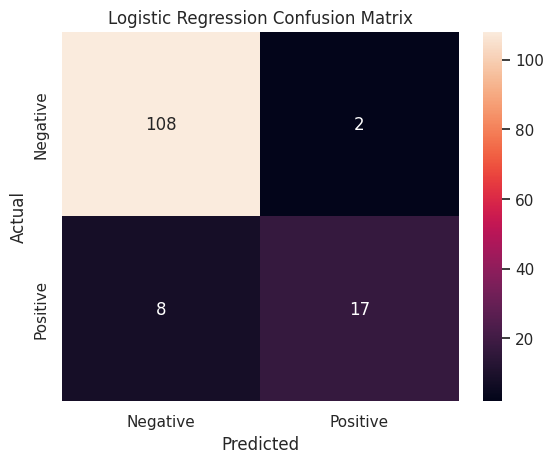

,accuracy,precision_positive,recall_positive,f1_positive
Multinomial Naive Bayes,0.814815,0.000000,0.00,0.000000
Logistic Regression,0.925926,0.894737,0.68,0.772727


In [11]:
models={'Multinomial Naive Bayes':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),max_features=25000,min_df=2)),('model',MultinomialNB())]),'Logistic Regression':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),max_features=25000,min_df=2)),('model',LogisticRegression(max_iter=1200,class_weight='balanced',random_state=42))])}
metrics={}
for name,model in models.items():
    model.fit(X_train,y_train); pred=model.predict(X_test)
    metrics[name]={'accuracy':accuracy_score(y_test,pred),'precision_positive':precision_score(y_test,pred,pos_label='Positive',zero_division=0),'recall_positive':recall_score(y_test,pred,pos_label='Positive',zero_division=0),'f1_positive':f1_score(y_test,pred,pos_label='Positive',zero_division=0)}
    print('\n',name,metrics[name]); print(classification_report(y_test,pred,zero_division=0))
    cm=confusion_matrix(y_test,pred,labels=['Negative','Positive']); sns.heatmap(cm,annot=True,fmt='d',xticklabels=['Negative','Positive'],yticklabels=['Negative','Positive']); plt.title(name+' Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()
display(pd.DataFrame(metrics).T)

In [12]:
best_model=models['Logistic Regression']
os.makedirs('artifacts',exist_ok=True)
joblib.dump(best_model,'artifacts/sentiment_model.joblib')
clean.to_csv('cleaned_reviews.csv',index=False)
print('Model and cleaned data saved.')

Model and cleaned data saved.


In [13]:
def predict_sentiment(review):
    return best_model.predict([clean_text(review)])[0]
tests=['I love the coffee and friendly staff.','The service was terrible and the drink was cold.','I do not like this coffee at all.','The place is nice and the staff were helpful.']
for sentence in tests: print(sentence,'=>',predict_sentiment(sentence))

I love the coffee and friendly staff. => Positive
The service was terrible and the drink was cold. => Negative
I do not like this coffee at all. => Negative
The place is nice and the staff were helpful. => Positive


### Conclusion
The original dataset had missing rating values and inconsistent rating formats may require normalization. Only review text and ratings were retained. Records with missing/invalid ratings and neutral ratings were removed for binary classification; duplicate pairs and empty cleaned text were also filtered. TF-IDF features were used to compare Naive Bayes and Logistic Regression. Logistic Regression was selected and exported with joblib; results depend on this dataset and may not generalize to other brands or review styles.